<a href="https://colab.research.google.com/github/gabrielcabanilla1/EXSU-500-Clinical-NLP-large-language-models-rct/blob/main/notebooks/04_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
PROJECT_DIR = '/content/drive/MyDrive/exsu_project'
PREDICTIONS_DIR = f'{PROJECT_DIR}/predictions'
RESULTS_DIR = f'{PROJECT_DIR}/results'
FIGURES_DIR = f'{RESULTS_DIR}/figures'
CLASSES = ['BACKGROUND', 'OBJECTIVE', 'METHODS', 'RESULTS', 'CONCLUSIONS']
SEED = 42
N_BOOTSTRAP = 2000
SPLIT = 'dev'
RUNS = {'position_baseline': 'Position baseline',
        'logreg_text': 'Logistic regression (sentence)',
        'logreg_context': 'Logistic regression (sentence + context)',
        'pubmedbert_text': 'PubMedBERT (sentence)',
        'pubmedbert_context': 'PubMedBERT (sentence + context)'}

In [4]:
import os
import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.metrics import f1_score, confusion_matrix

drive.mount('/content/drive')
os.makedirs(FIGURES_DIR, exist_ok=True)

available = [r for r in RUNS if os.path.exists(f'{RESULTS_DIR}/{SPLIT}_{r}_summary.csv')]
missing = [r for r in RUNS if r not in available]
print('Runs found:', available)
print('Runs missing (run their notebook first):', missing or 'none')

summaries = pd.concat([pd.read_csv(f'{RESULTS_DIR}/{SPLIT}_{r}_summary.csv') for r in available]).set_index('run')
per_class = {r: pd.read_csv(f'{RESULTS_DIR}/{SPLIT}_{r}_per_class.csv', index_col=0) for r in available}
predictions = {r: pd.read_csv(f'{PREDICTIONS_DIR}/{SPLIT}_{r}.csv', dtype={'abstract_id': str}, keep_default_na=False)
               .sort_values(['abstract_id', 'sentence_idx']).reset_index(drop=True) for r in available}
reference = predictions[available[0]]
for r in available:
    assert (predictions[r][['abstract_id', 'sentence_idx', 'label']].values ==
            reference[['abstract_id', 'sentence_idx', 'label']].values).all(), f'{r}: different sentences'
y_true = pd.Categorical(reference.label, categories=CLASSES).codes
preds = {r: pd.Categorical(predictions[r].prediction, categories=CLASSES).codes for r in available}
print(f'{len(reference):,} {SPLIT} sentences, identical in every run')

Mounted at /content/drive
Runs found: ['position_baseline', 'logreg_text', 'logreg_context', 'pubmedbert_text', 'pubmedbert_context']
Runs missing (run their notebook first): none
30,212 dev sentences, identical in every run


In [5]:
columns = ['macro_f1', 'macro_f1_ci95_lower', 'macro_f1_ci95_upper', 'accuracy', 'weighted_f1',
           'macro_auroc', 'macro_auprc', 'macro_sensitivity', 'macro_specificity', 'fit_seconds', 'hardware']
comparison = summaries[columns].copy()
comparison.insert(0, 'model', [RUNS[r] for r in comparison.index])
comparison.to_csv(f'{RESULTS_DIR}/{SPLIT}_model_comparison.csv')
display(comparison.round(4))

per_class_f1 = pd.DataFrame({RUNS[r]: per_class[r].loc[CLASSES, 'f1'] for r in available}).T
per_class_f1.to_csv(f'{RESULTS_DIR}/{SPLIT}_per_class_f1.csv')
print('F1 by class:')
display(per_class_f1.round(3))

,model,macro_f1,macro_f1_ci95_lower,macro_f1_ci95_upper,accuracy,weighted_f1,macro_auroc,macro_auprc,macro_sensitivity,macro_specificity,fit_seconds,hardware
run,,,,,,,,,,,,
position_baseline,Position baseline,0.6088,0.6029,0.6147,0.6923,0.6756,0.9158,0.6252,0.6188,0.9167,0.0,CPU (8 cores)
logreg_text,Logistic regression (sentence),0.7702,0.7634,0.7770,0.8334,0.8313,0.9633,0.8307,0.7626,0.9570,152.9,CPU (2 cores)
logreg_context,Logistic regression (sentence + context),0.8519,0.8454,0.8583,0.9010,0.8998,0.9854,0.9087,0.8472,0.9747,367.1,CPU (2 cores)
pubmedbert_text,PubMedBERT (sentence),0.8372,0.8309,0.8437,0.8901,0.8894,0.9822,0.9011,0.8332,0.9724,1218.0,NVIDIA L4
pubmedbert_context,PubMedBERT (sentence + context),0.8850,0.8787,0.8912,0.9326,0.9319,0.9913,0.9389,0.8822,0.9835,2586.0,NVIDIA L4


F1 by class:


class,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
Position baseline,0.255,0.528,0.732,0.756,0.772
Logistic regression (sentence),0.659,0.622,0.908,0.894,0.769
Logistic regression (sentence + context),0.778,0.669,0.946,0.938,0.928
PubMedBERT (sentence),0.760,0.676,0.952,0.934,0.864
PubMedBERT (sentence + context),0.812,0.701,0.974,0.970,0.968


In [6]:
def paired_bootstrap(run_a, run_b, y_true, preds, abstract_ids, n_resamples=N_BOOTSTRAP, seed=SEED):
    index, unique_ids = pd.factorize(pd.Series(abstract_ids))
    k = len(CLASSES)
    counts = {}
    for run in (run_a, run_b):
        counts[run] = np.zeros((len(unique_ids), k, k), dtype=np.int64)
        np.add.at(counts[run], (index, y_true, preds[run]), 1)

    def macro_f1(cm):
        denominator = cm.sum(axis=0) + cm.sum(axis=1)
        return np.divide(2 * np.diag(cm), denominator, out=np.zeros(k), where=denominator > 0).mean()

    rng = np.random.default_rng(seed)
    differences = np.empty(n_resamples)
    for b in range(n_resamples):
        sample = rng.integers(0, len(unique_ids), len(unique_ids))
        differences[b] = macro_f1(counts[run_a][sample].sum(axis=0)) - macro_f1(counts[run_b][sample].sum(axis=0))
    point = macro_f1(counts[run_a].sum(axis=0)) - macro_f1(counts[run_b].sum(axis=0))
    lower, upper = np.percentile(differences, [2.5, 97.5])
    return {'comparison': f'{run_a} - {run_b}', 'difference': point, 'ci95_lower': lower, 'ci95_upper': upper,
            'ci_excludes_zero': bool(lower > 0 or upper < 0)}

PAIRS = [('logreg_text', 'position_baseline'), ('logreg_context', 'logreg_text'),
         ('pubmedbert_text', 'logreg_text'), ('pubmedbert_context', 'pubmedbert_text'),
         ('pubmedbert_context', 'logreg_context')]

differences = pd.DataFrame([paired_bootstrap(a, b, y_true, preds, reference.abstract_id)
                            for a, b in PAIRS if a in available and b in available])
differences.to_csv(f'{RESULTS_DIR}/{SPLIT}_paired_differences.csv', index=False)
print('Paired bootstrap over whole abstracts (difference in macro-F1, first minus second):')
display(differences.round(4))

Paired bootstrap over whole abstracts (difference in macro-F1, first minus second):


,comparison,difference,ci95_lower,ci95_upper,ci_excludes_zero
0,logreg_text - position_baseline,0.1614,0.1533,0.1700,True
1,logreg_context - logreg_text,0.0817,0.0764,0.0870,True
2,pubmedbert_text - logreg_text,0.0670,0.0616,0.0728,True
3,pubmedbert_context - pubmedbert_text,0.0478,0.0425,0.0528,True
4,pubmedbert_context - logreg_context,0.0331,0.0278,0.0381,True


In [7]:
import matplotlib.pyplot as plt
CLASS_COLORS = dict(zip(CLASSES, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']))
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#3d3c38', 'xtick.color': '#5c5b56',
                     'ytick.color': '#5c5b56', 'legend.frameon': False})

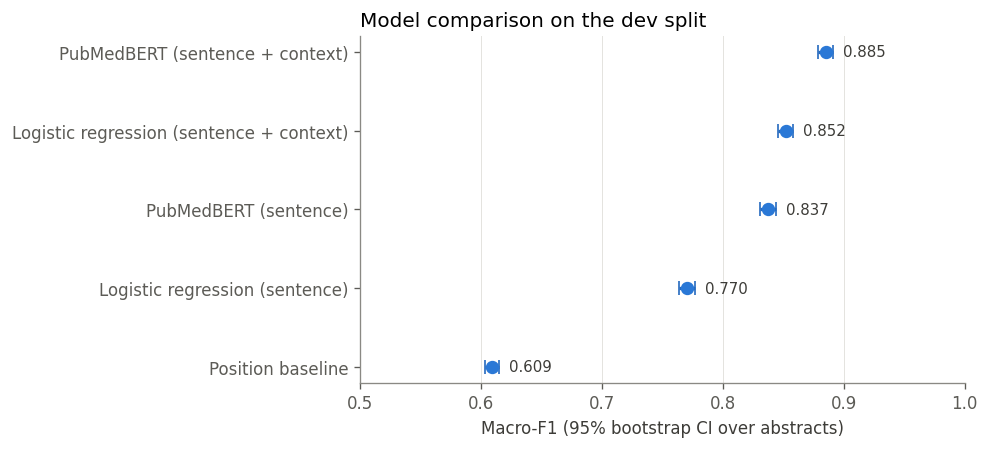

In [8]:
order = comparison.sort_values('macro_f1').index
fig, ax = plt.subplots(figsize=(6.5, 0.55 * len(order) + 1))
y = np.arange(len(order))
ax.errorbar(comparison.loc[order, 'macro_f1'], y,
            xerr=[comparison.loc[order, 'macro_f1'] - comparison.loc[order, 'macro_f1_ci95_lower'],
                  comparison.loc[order, 'macro_f1_ci95_upper'] - comparison.loc[order, 'macro_f1']],
            fmt='o', color='#2a78d6', ecolor='#256abf', elinewidth=2, capsize=4, markersize=7)
for yi, r in zip(y, order):
    ax.annotate(f"{comparison.loc[r, 'macro_f1']:.3f}", (comparison.loc[r, 'macro_f1_ci95_upper'], yi),
                xytext=(6, 0), textcoords='offset points', va='center', fontsize=9, color='#3d3c38')
ax.set_yticks(y, [RUNS[r] for r in order])
ax.set_xlabel('Macro-F1 (95% bootstrap CI over abstracts)')
ax.set_title(f'Model comparison on the {SPLIT} split', loc='left')
ax.grid(axis='y', visible=False)
ax.set_xlim(min(0.5, comparison.macro_f1_ci95_lower.min() - 0.03), 1.0)
fig.savefig(f'{FIGURES_DIR}/{SPLIT}_fig_model_comparison.png')
plt.show()

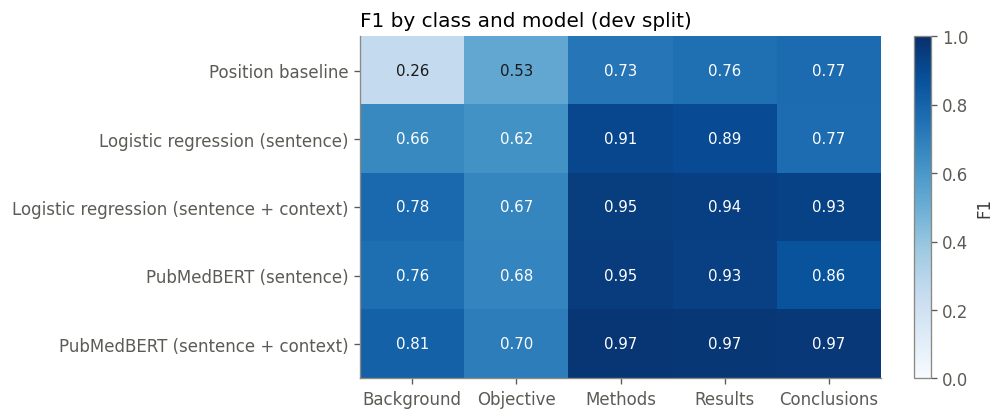

In [9]:
fig, ax = plt.subplots(figsize=(7, 0.5 * len(per_class_f1) + 1.2))
image = ax.imshow(per_class_f1.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for i in range(per_class_f1.shape[0]):
    for j in range(per_class_f1.shape[1]):
        value = per_class_f1.values[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=9,
                color='white' if value > 0.6 else '#1a1a19')
ax.set_xticks(range(len(CLASSES)), [c.capitalize() for c in CLASSES])
ax.set_yticks(range(len(per_class_f1)), per_class_f1.index)
ax.grid(False)
fig.colorbar(image, ax=ax, label='F1')
ax.set_title(f'F1 by class and model ({SPLIT} split)', loc='left')
fig.savefig(f'{FIGURES_DIR}/{SPLIT}_fig_per_class_f1.png')
plt.show()

Best model on this split: PubMedBERT (sentence + context)


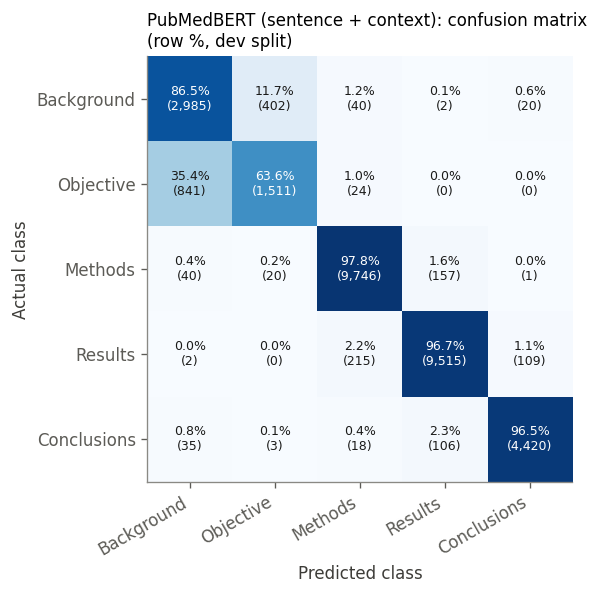

In [10]:
best = comparison.macro_f1.idxmax()
print('Best model on this split:', RUNS[best])
cm = confusion_matrix(y_true, preds[best], labels=range(len(CLASSES)))
cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.imshow(cm_percent, cmap='Blues', vmin=0, vmax=100)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f'{cm_percent[i, j]:.1f}%\n({cm[i, j]:,})', ha='center', va='center', fontsize=7.5,
                color='white' if cm_percent[i, j] > 60 else '#1a1a19')
ax.set_xticks(range(len(CLASSES)), [c.capitalize() for c in CLASSES], rotation=30, ha='right')
ax.set_yticks(range(len(CLASSES)), [c.capitalize() for c in CLASSES])
ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
ax.grid(False)
ax.set_title(f'{RUNS[best]}: confusion matrix\n(row %, {SPLIT} split)', loc='left', fontsize=10)
fig.savefig(f'{FIGURES_DIR}/{SPLIT}_fig_confusion_best.png')
plt.show()

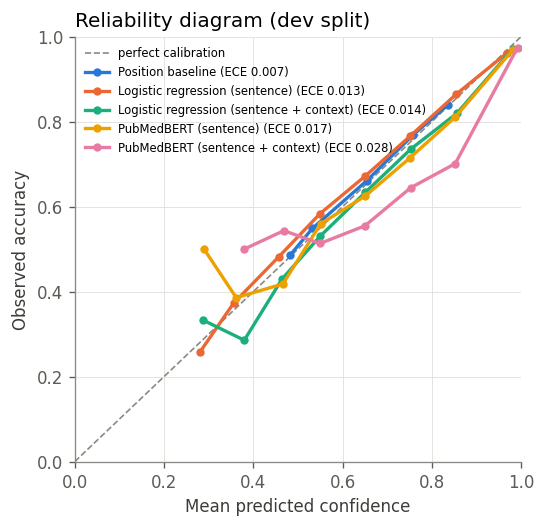

,run,model,expected_calibration_error
0,position_baseline,Position baseline,0.0072
1,logreg_text,Logistic regression (sentence),0.0128
2,logreg_context,Logistic regression (sentence + context),0.0142
3,pubmedbert_text,PubMedBERT (sentence),0.0175
4,pubmedbert_context,PubMedBERT (sentence + context),0.0279


In [11]:
def reliability(probs, y, n_bins=10):
    confidence = probs.max(axis=1)
    correct = probs.argmax(axis=1) == y
    bins = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    table = pd.DataFrame({'bin': bins, 'confidence': confidence, 'correct': correct}).groupby('bin').agg(
        sentences=('correct', 'size'), mean_confidence=('confidence', 'mean'), accuracy=('correct', 'mean'))
    ece = (table.sentences / len(y) * (table.accuracy - table.mean_confidence).abs()).sum()
    return table, ece

calibration_rows = []
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot([0, 1], [0, 1], color='#8a8984', linewidth=1, linestyle='--', label='perfect calibration')
RUN_COLORS = dict(zip(RUNS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']))
for r in [r for r in RUNS if r in available]:
    color = RUN_COLORS[r]
    probs = predictions[r][[f'prob_{c}' for c in CLASSES]].to_numpy()
    table, ece = reliability(probs, y_true)
    calibration_rows.append({'run': r, 'model': RUNS[r], 'expected_calibration_error': ece})
    ax.plot(table.mean_confidence, table.accuracy, marker='o', markersize=4, linewidth=2, color=color,
            label=f'{RUNS[r]} (ECE {ece:.3f})')
ax.set_xlabel('Mean predicted confidence')
ax.set_ylabel('Observed accuracy')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title(f'Reliability diagram ({SPLIT} split)', loc='left')
ax.legend(fontsize=7, loc='upper left')
fig.savefig(f'{FIGURES_DIR}/{SPLIT}_fig_reliability.png')
plt.show()
calibration = pd.DataFrame(calibration_rows)
calibration.to_csv(f'{RESULTS_DIR}/{SPLIT}_calibration.csv', index=False)
display(calibration.round(4))